# SciCite: Citation Intent Classification
## 01. Exploratory Data Analysis & Preprocessing Pipeline

**Course:** Mesterséges intelligencia alkalmazási területei (MSc)
**Dataset:** `allenai/scicite` (Official splits from NAACL 2019 / Hugging Face)
**Target Classes (3):** `background`, `method`, `result`
**Objective:** Inspect split integrity, justify the retention of official partitions, analyze class imbalance, normalize the noisy `sectionName` feature, and construct comparative input representations (`text-only` vs. `section-aware`).

In [1]:
# 1. Environment & Reproducibility Setup
import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.seed import set_seed
from src.data_processing.loader import load_scicite_dataset, get_label_mappings, dataset_to_dataframes
from src.data_processing.eda import compute_split_summary, compute_class_distribution, analyze_sections
from src.data_processing.preprocess import build_input_representations, normalize_section_name
from src.utils.visualizer import (
    plot_class_distribution,
    plot_top_sections,
    plot_section_label_contingency,
    plot_canonical_section_distribution,
    plot_canonical_section_contingency,
)

set_seed(42)
print("Environment initialized and seed set to 42.")

C:\Repos\scicite-citation-intent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment initialized and seed set to 42.


### 2. Dataset Loading & Methodological Rationale for Official Splits
In many standard machine learning workflows, a common starting step is merging all available data and performing a random split (e.g. `train_test_split(shuffle=True)`). However, in this project we **strictly retain the official predefined partitions** established by Cohan et al. (NAACL 2019).

#### Why Official Splits Are Essential:
1. **Prevention of Document-Level Data Leakage (Group Leakage):**
   - Citations in SciCite are extracted from scientific papers (`citingPaperId`). A single paper often contains multiple citation sentences written by the same authors, sharing identical topic context, terminology, and stylistic patterns.
   - A naive random row-level split would scatter citations from the *same paper* across both training and test sets. The model would easily 'memorize' paper-specific lexical clues, resulting in overly optimistic, artificially inflated evaluation scores.
   - The official partitions are partitioned at the paper level, guaranteeing that test instances evaluate true out-of-domain generalization.

2. **Direct Benchmark Comparability (Literature Ground Truth):**
   - Seminal papers (e.g., SciCite / Cohan et al., 2019; SciBERT / Beltagy et al., 2019) report their baseline and state-of-the-art results (~84.0% Macro-F1) on this exact official test split.
   - Retaining the official partitions allows our experimental results (DistilBERT vs. SciBERT) to be benchmarked directly against peer-reviewed published literature.

3. **Course Specification Alignment:**
   - Preserving the official split directly fulfills the approved research scope submitted to the course instructor.

In [2]:
dataset = load_scicite_dataset()
id2label, label2id = get_label_mappings(dataset)
dfs = dataset_to_dataframes(dataset)

print("Dataset splits loaded successfully:")
for split_name, df in dfs.items():
    print(f"  - {split_name.capitalize():<12}: {len(df):>5} samples")
print(f"\nLabel mappings (id2label): {id2label}")

Dataset splits loaded successfully:
  - Train       :  8194 samples
  - Validation  :   916 samples
  - Test        :  1859 samples

Label mappings (id2label): {0: 'method', 1: 'background', 2: 'result'}


### 3. Split Summary & Data Integrity Check
Examining row counts, unique citing/cited paper counts, and missingness across splits.

In [3]:
split_summary = compute_split_summary(dfs)
split_summary

,split,total_samples,unique_citing_papers,unique_cited_papers,missing_string,missing_section,section_missing_pct
0,train,8194,4664,4557,0,587,7.16
1,validation,916,817,802,0,71,7.75
2,test,1859,1845,1804,0,66,3.55


### 4. Label Distribution & Class Imbalance Analysis
The target variable `label` exhibits substantial class imbalance:
- `background` represents the majority class (~59%)
- `method` represents ~28%
- `result` represents the minority class (~13%)

Because of this imbalance, standard **Accuracy** can be misleading (a trivial majority classifier achieves ~59% accuracy). Thus, **Macro-F1** is selected as the primary optimization and comparison metric.

     split  label_id label_name  count  percentage
     train         0     method   2266       27.65
     train         1 background   4840       59.07
     train         2     result   1088       13.28
validation         0     method    255       27.84
validation         1 background    538       58.73
validation         2     result    123       13.43
      test         0     method    604       32.49
      test         1 background    996       53.58
      test         2     result    259       13.93


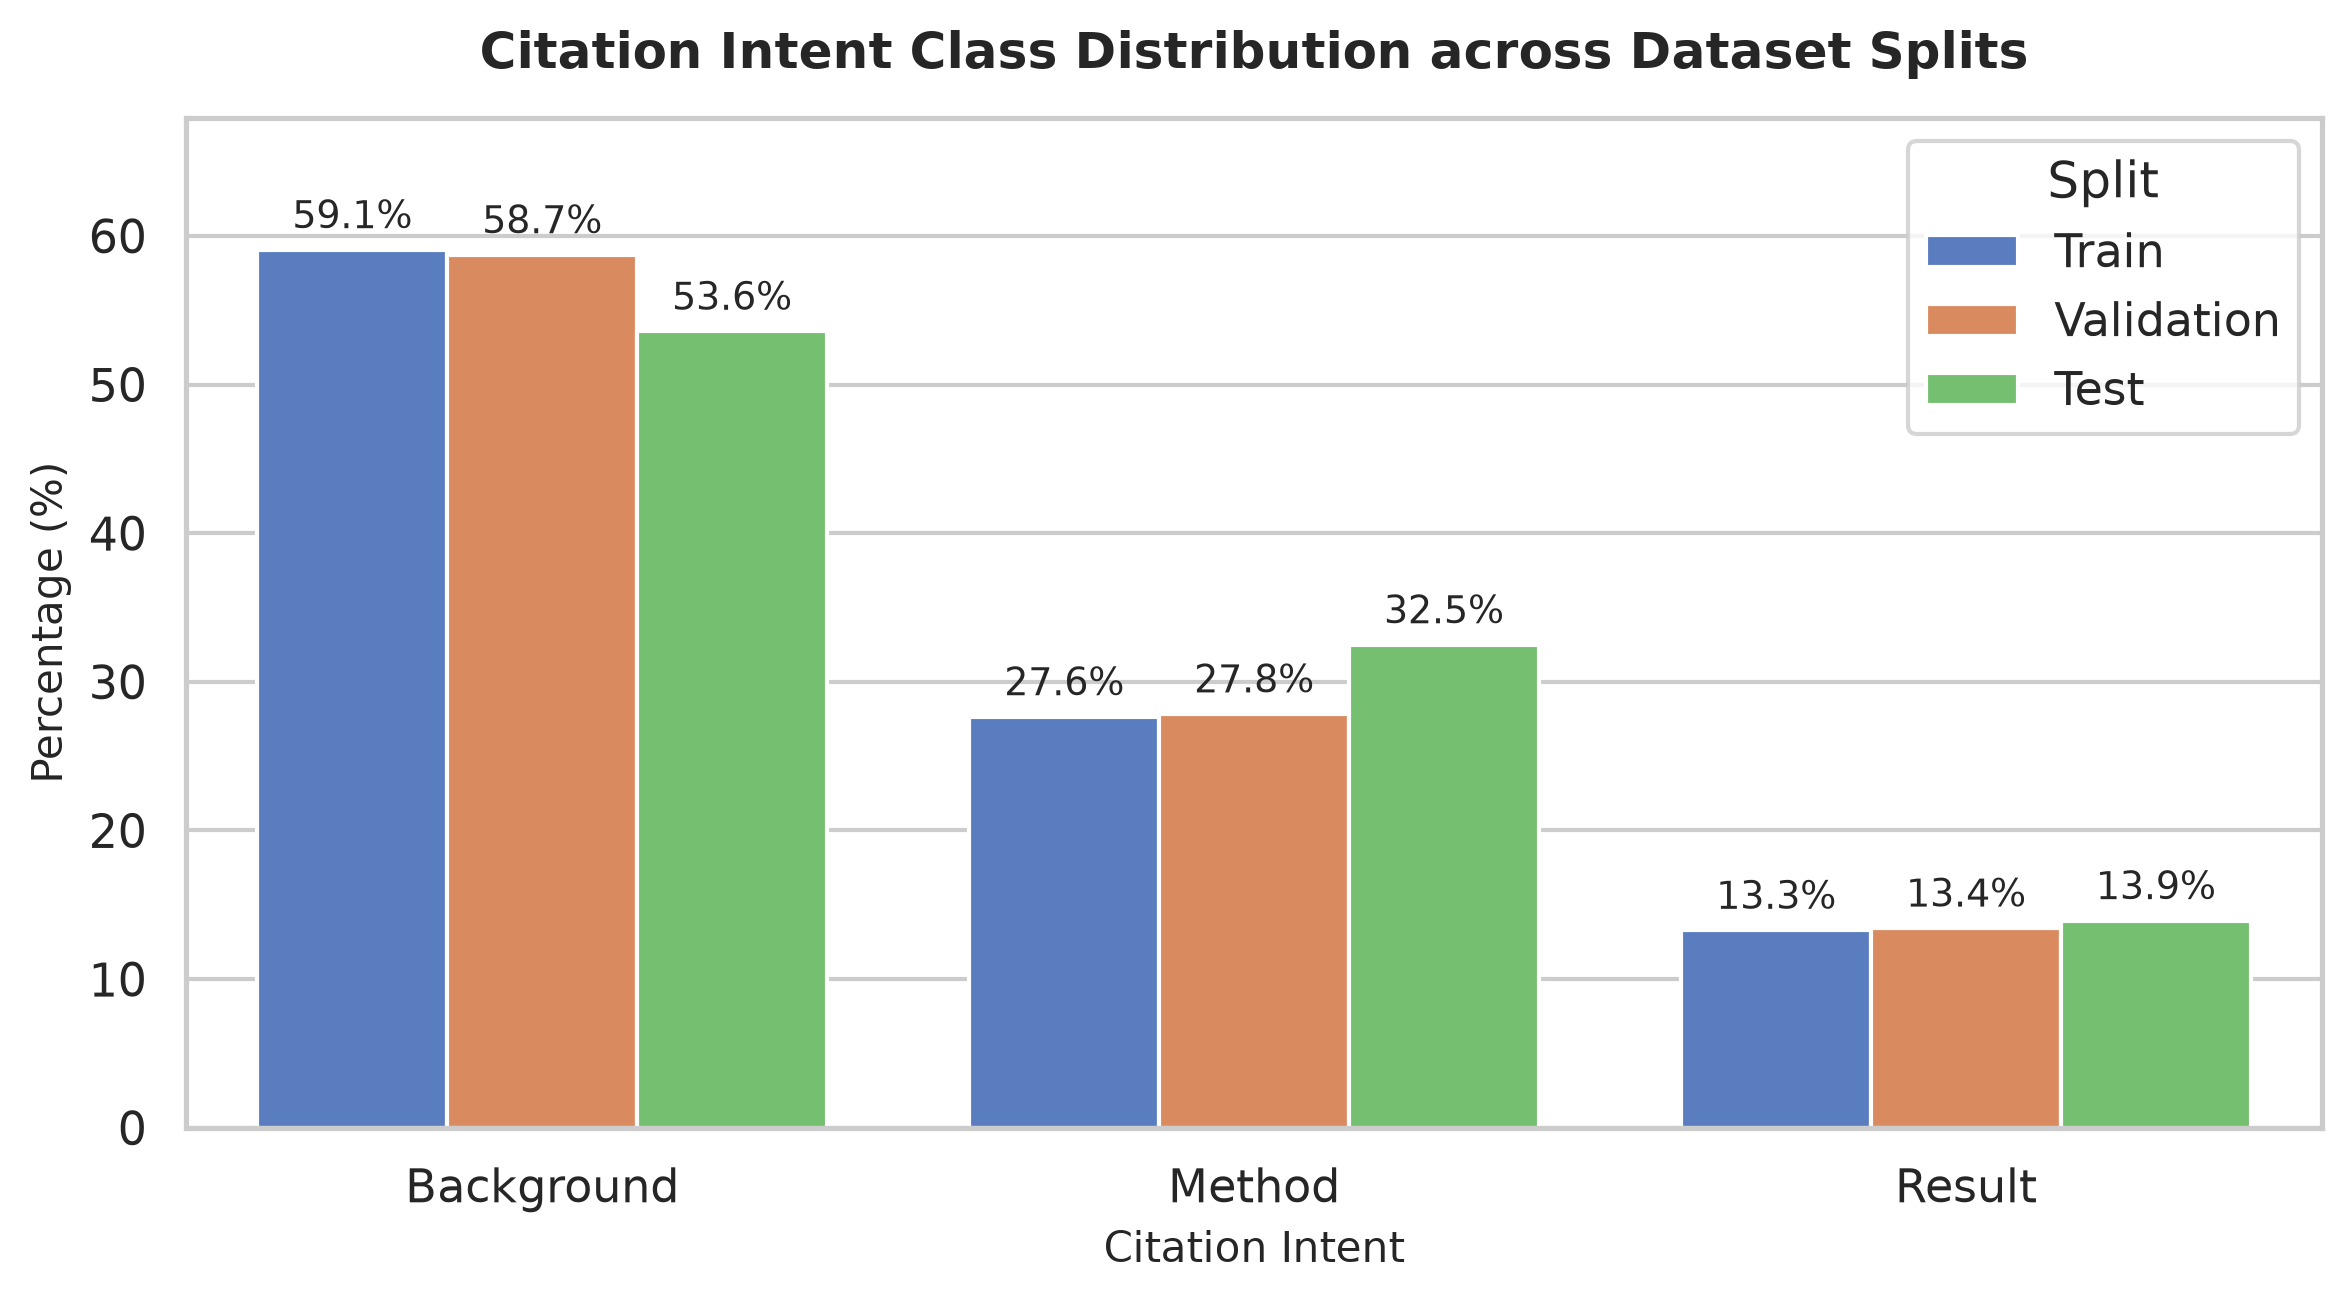

In [4]:
class_dist = compute_class_distribution(dfs, id2label)
print(class_dist.to_string(index=False))

# Plot class distributions
fig = plot_class_distribution(dfs, id2label)
plt.show()

### 5. Section Name Investigation & Noise Quantification
The `sectionName` field provides crucial structural context: an in-text citation appearing in an *'Introduction'* section has a much higher prior probability of being `background`, whereas a citation in *'Materials and Methods'* strongly implies `method`.

However, real scientific manuscripts use disparate formatting, numbering schemes, typos, and abbreviations.

--- Section Name Diagnostics (Train Split) ---
Total samples:                     8194
Missing / empty headers:          587 (7.16%)
Unique raw headers:               1147
Singletons (appear exactly once): 809 (70.53%)
Headers with numerical prefixes:  1980 (26.03%)
Headers in uppercase:             1556 (20.45%


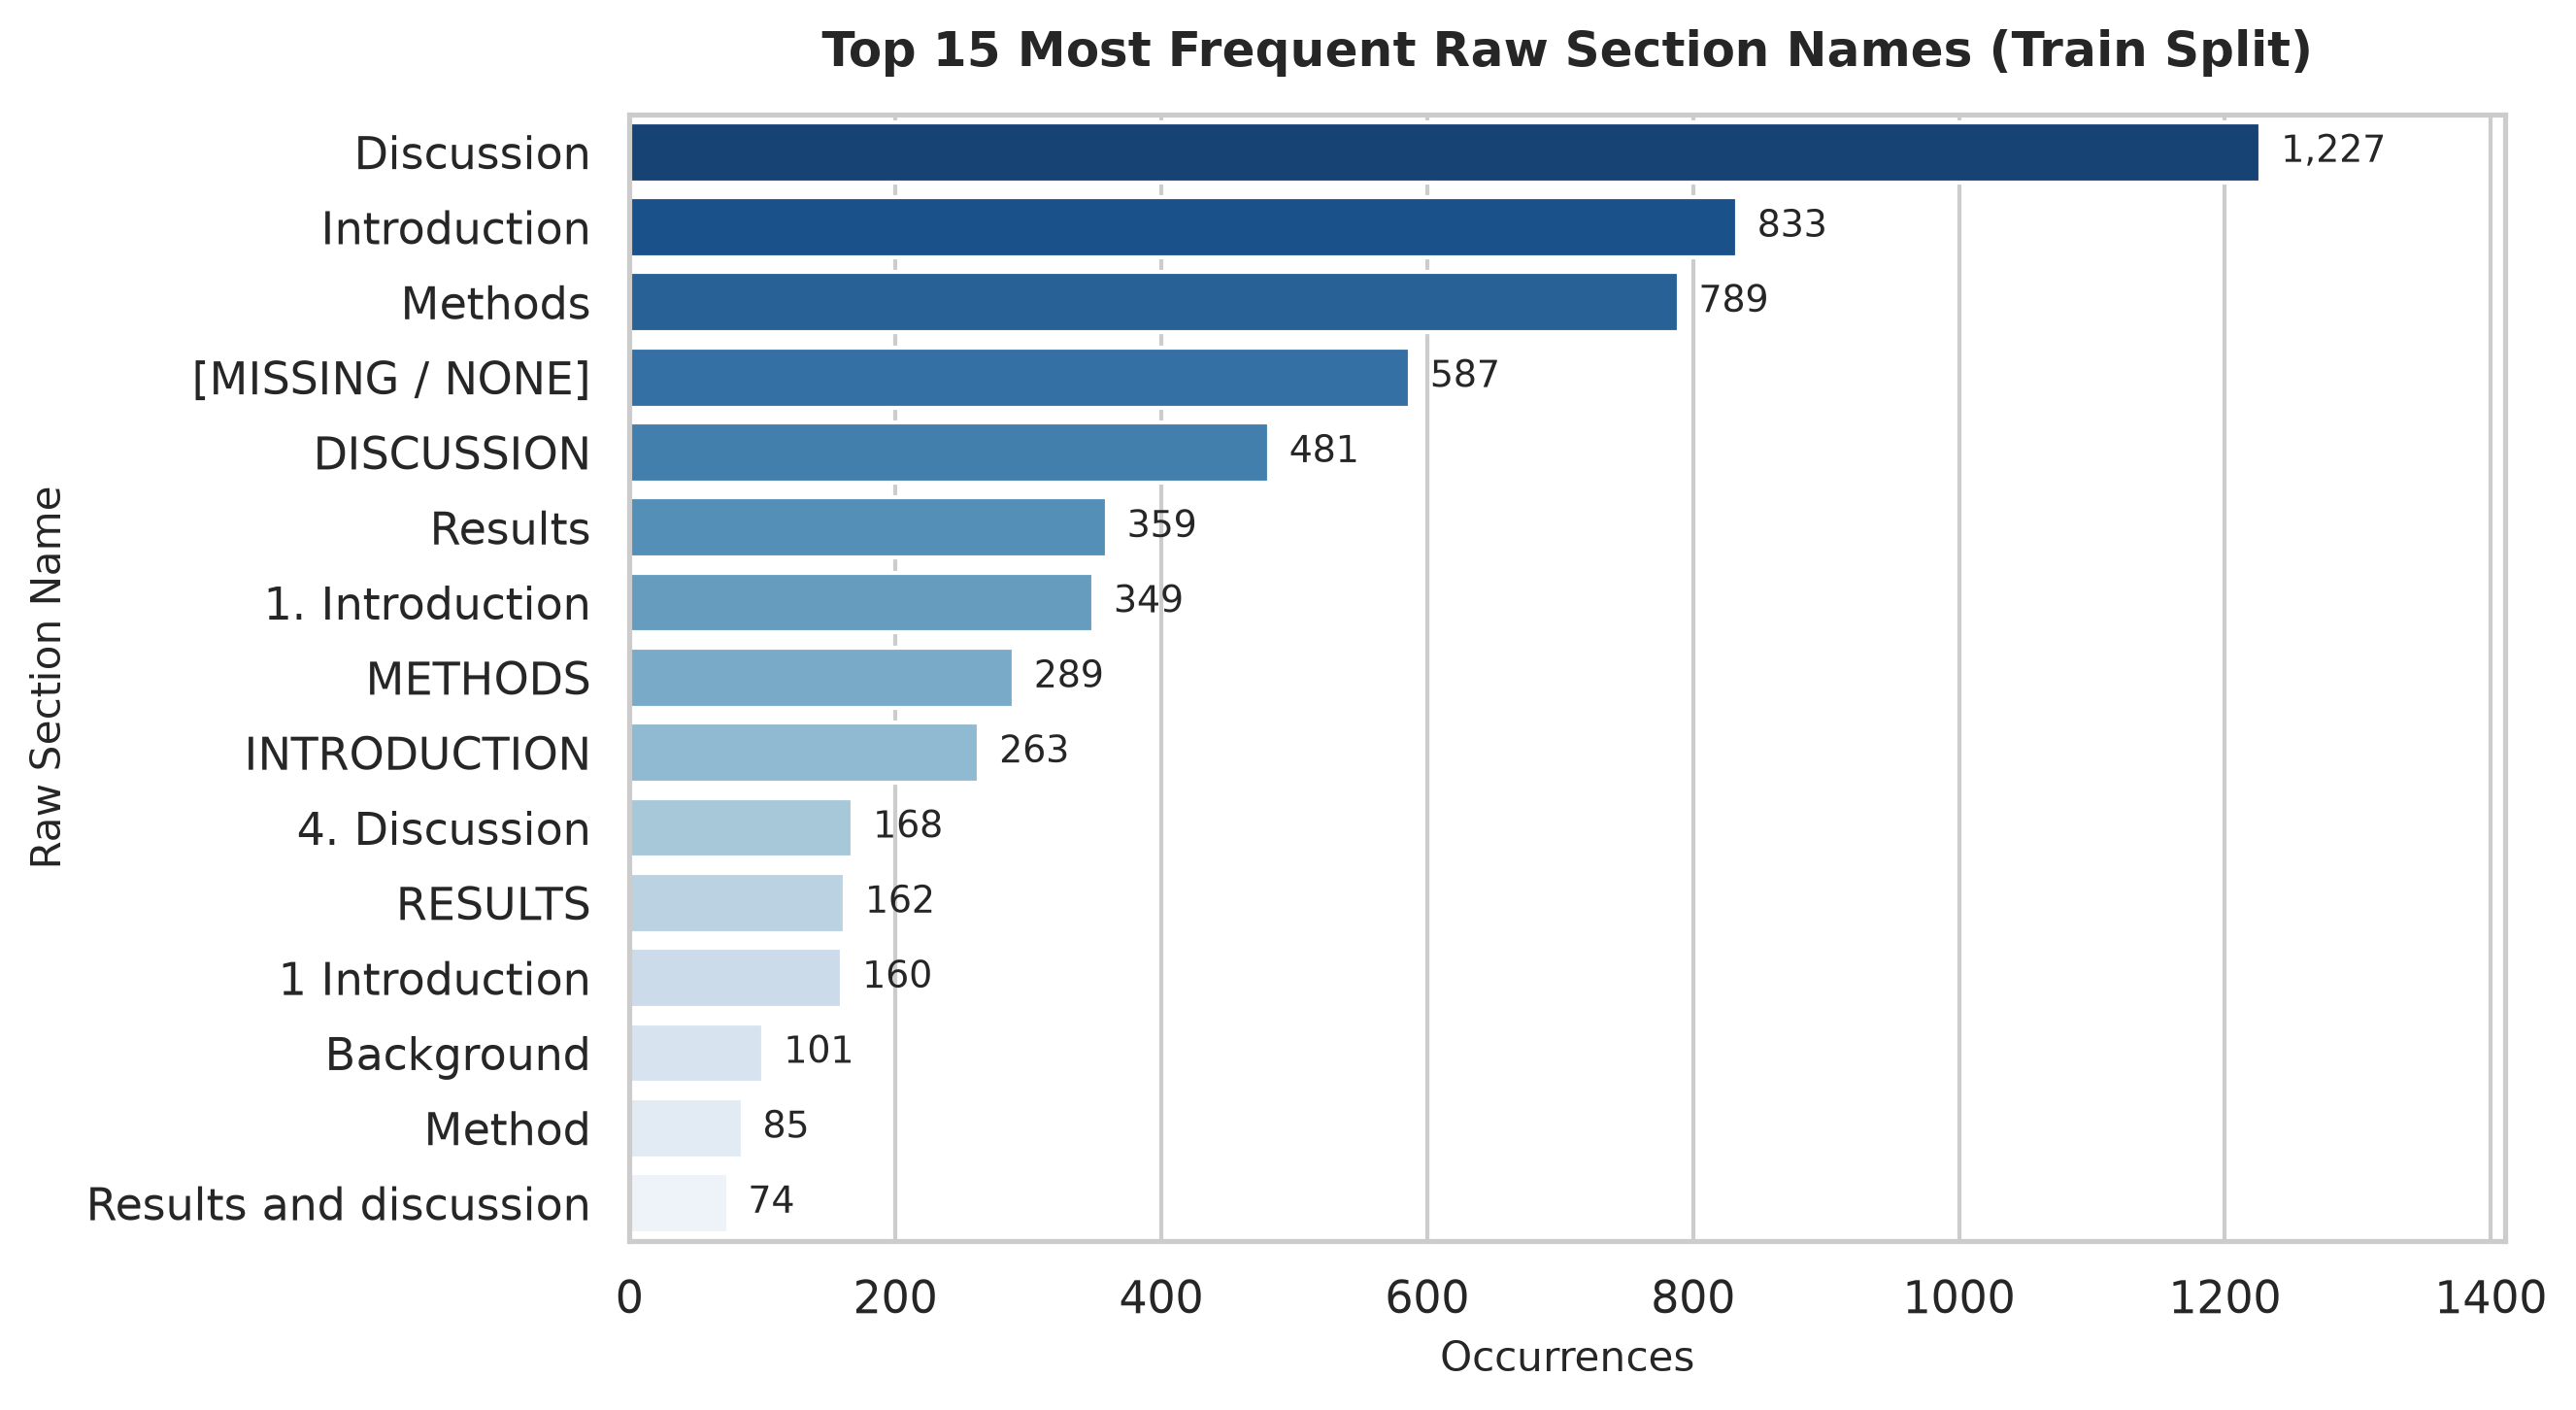

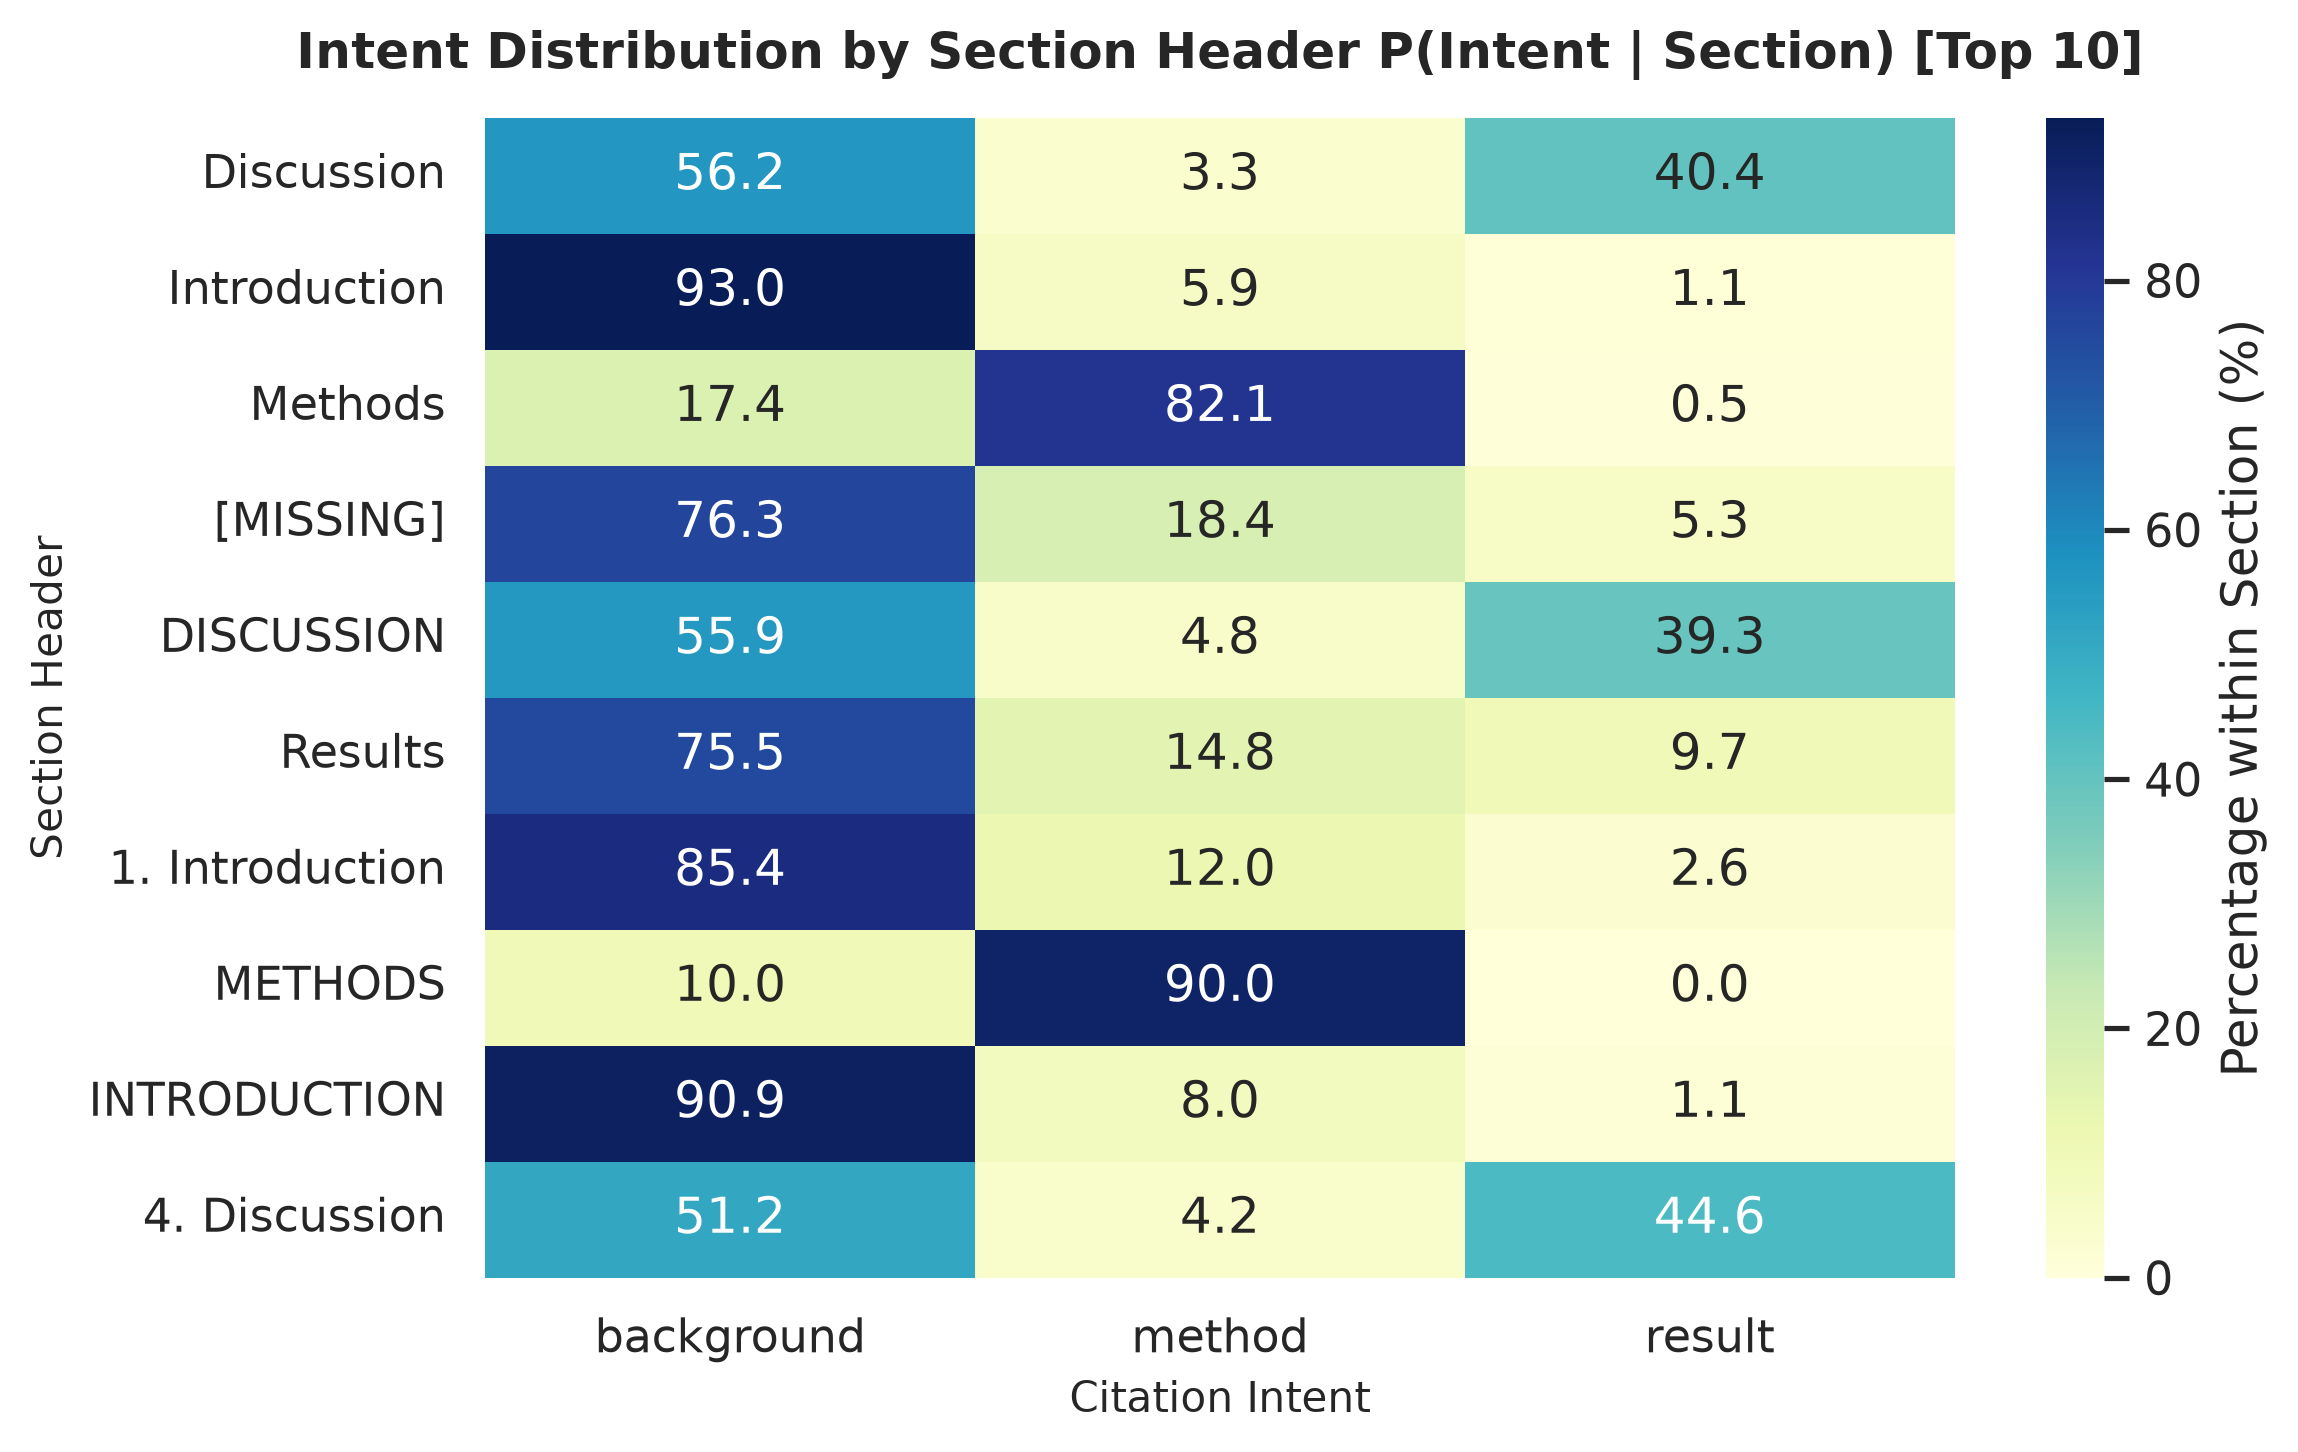

In [5]:
section_metrics = analyze_sections(dfs["train"])

print("--- Section Name Diagnostics (Train Split) ---")
print(f"Total samples:                     {section_metrics['total_samples']}")
print(f"Missing / empty headers:          {section_metrics['missing_or_empty']} ({section_metrics['missing_percentage']}%)")
print(f"Unique raw headers:               {section_metrics['unique_raw_sections']}")
print(f"Singletons (appear exactly once): {section_metrics['singletons_appearing_once']} ({section_metrics['singletons_percentage']}%)")
print(f"Headers with numerical prefixes:  {section_metrics['noise_leading_numbers']} ({section_metrics['noise_leading_numbers_pct']}%)")
print(f"Headers in uppercase:             {section_metrics['all_uppercase']} ({section_metrics['all_uppercase_pct']}%")

fig = plot_top_sections(dfs["train"], top_n=15)
plt.show()

fig = plot_section_label_contingency(dfs["train"], id2label, top_n=10)
plt.show()

### 6. Section Normalization Pipeline & Comparative Representations
Based on the noise patterns identified above, we map all raw section strings into seven canonical categories:
`introduction`, `method`, `result`, `discussion`, `result_discussion`, `other`, `missing`.

We then generate two comparative input representations:
1. **Text-only:** `[string]` (raw citation sentence only)
2. **Section-aware:** `Section: [canonical_section]. Citation: [string]` (context-enhanced prefix conditioning)

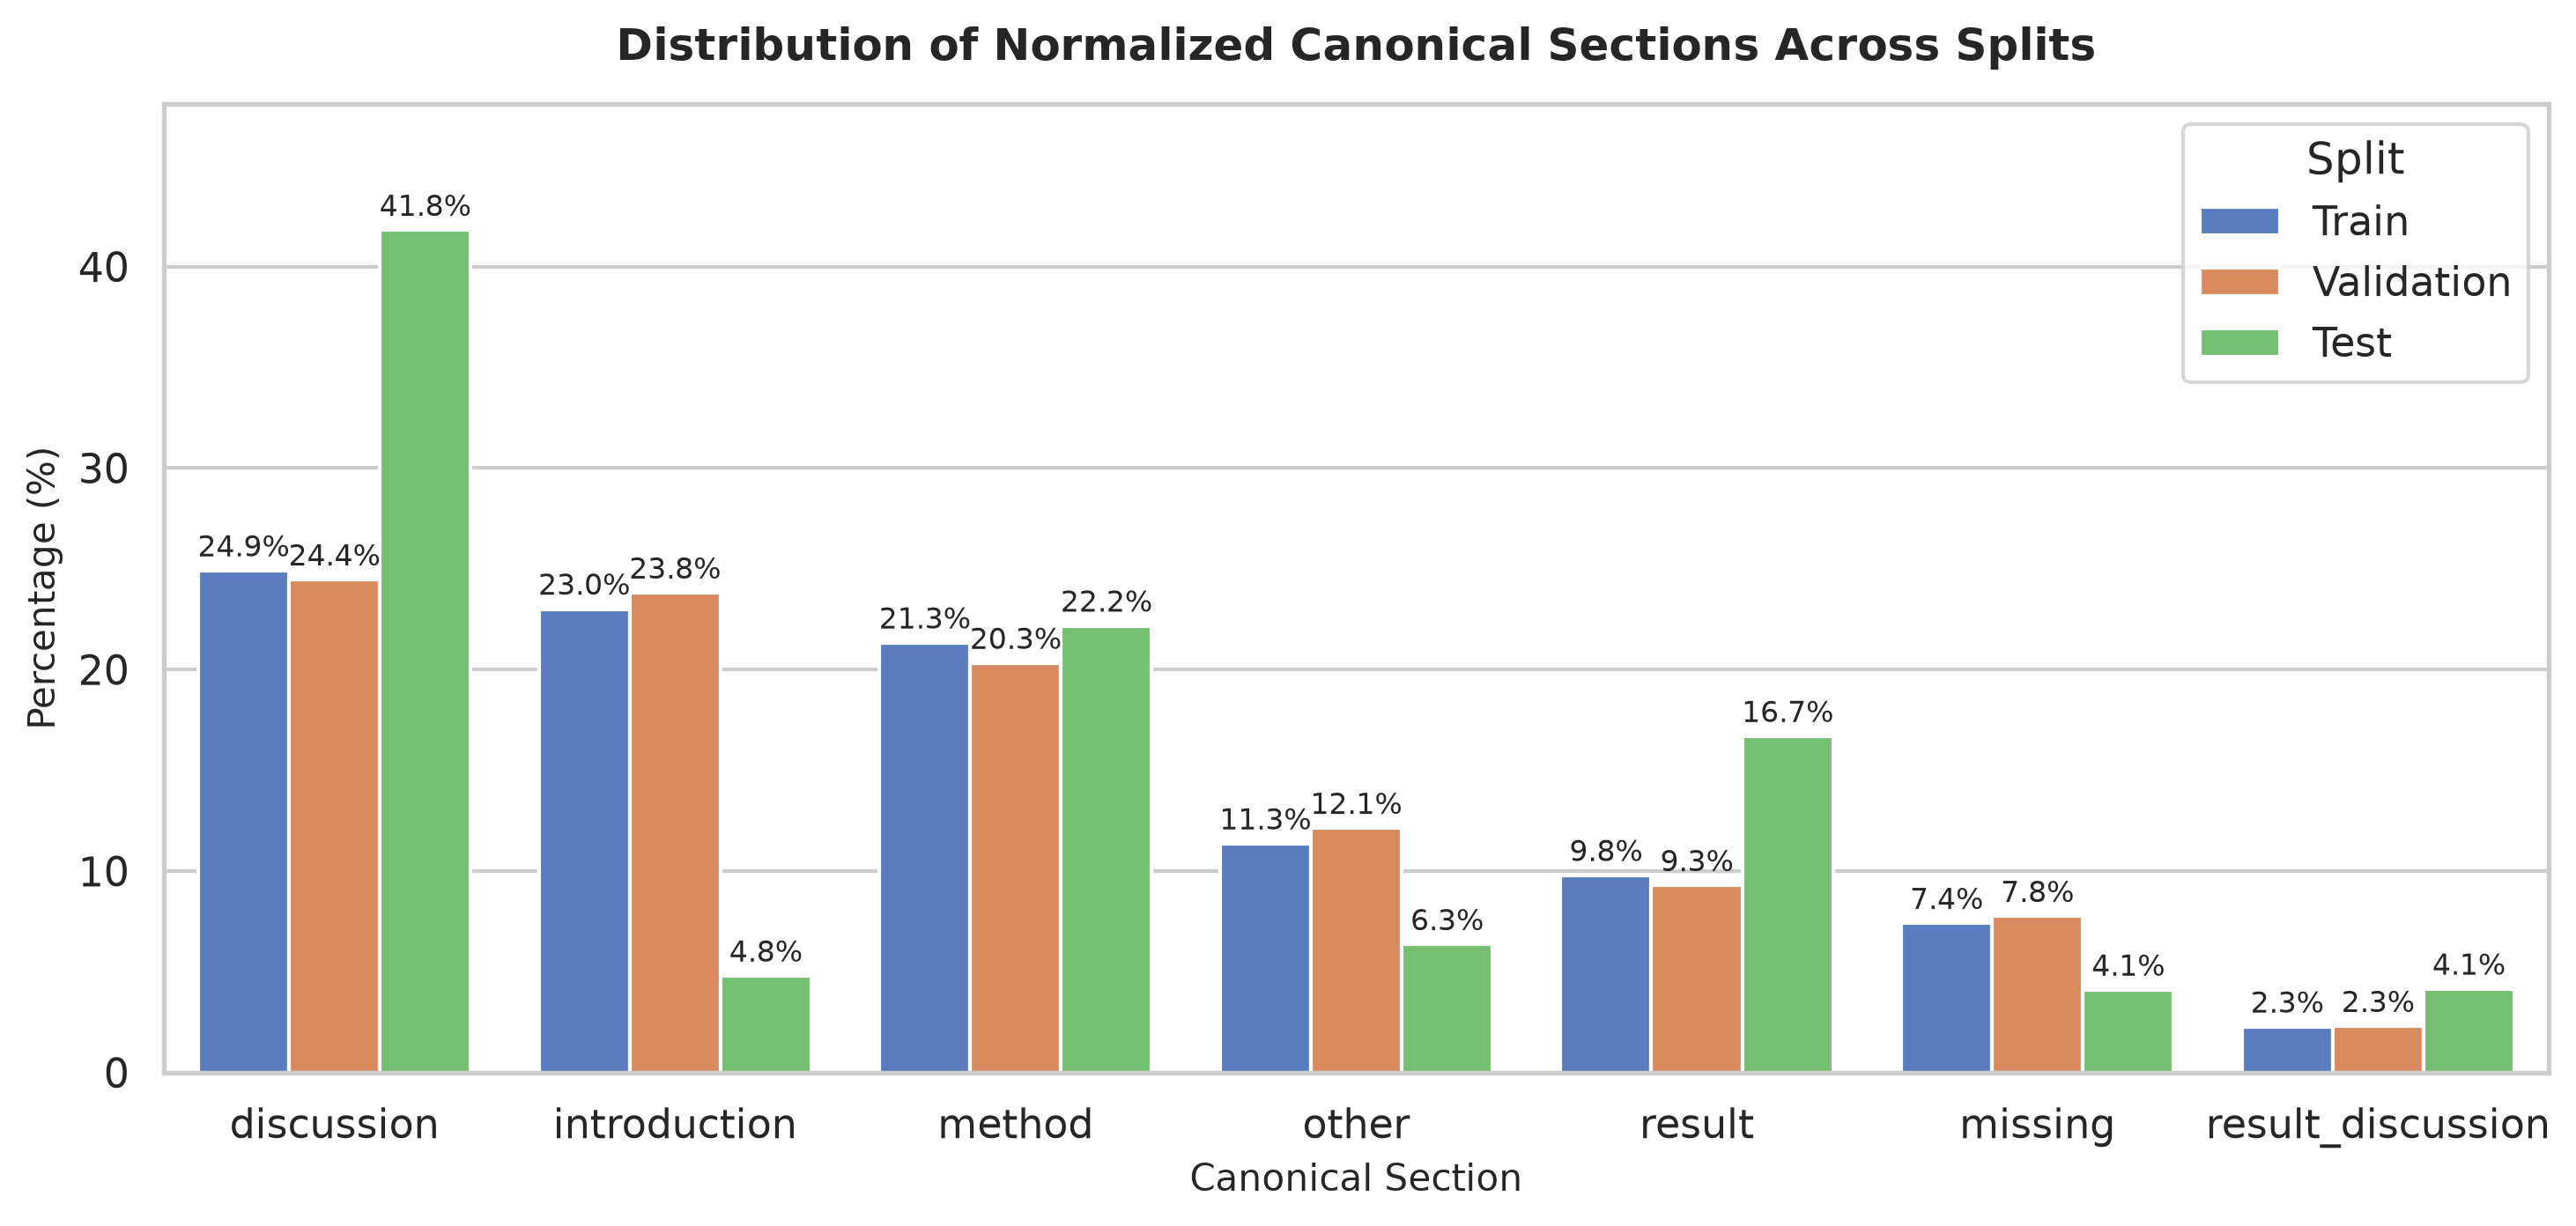

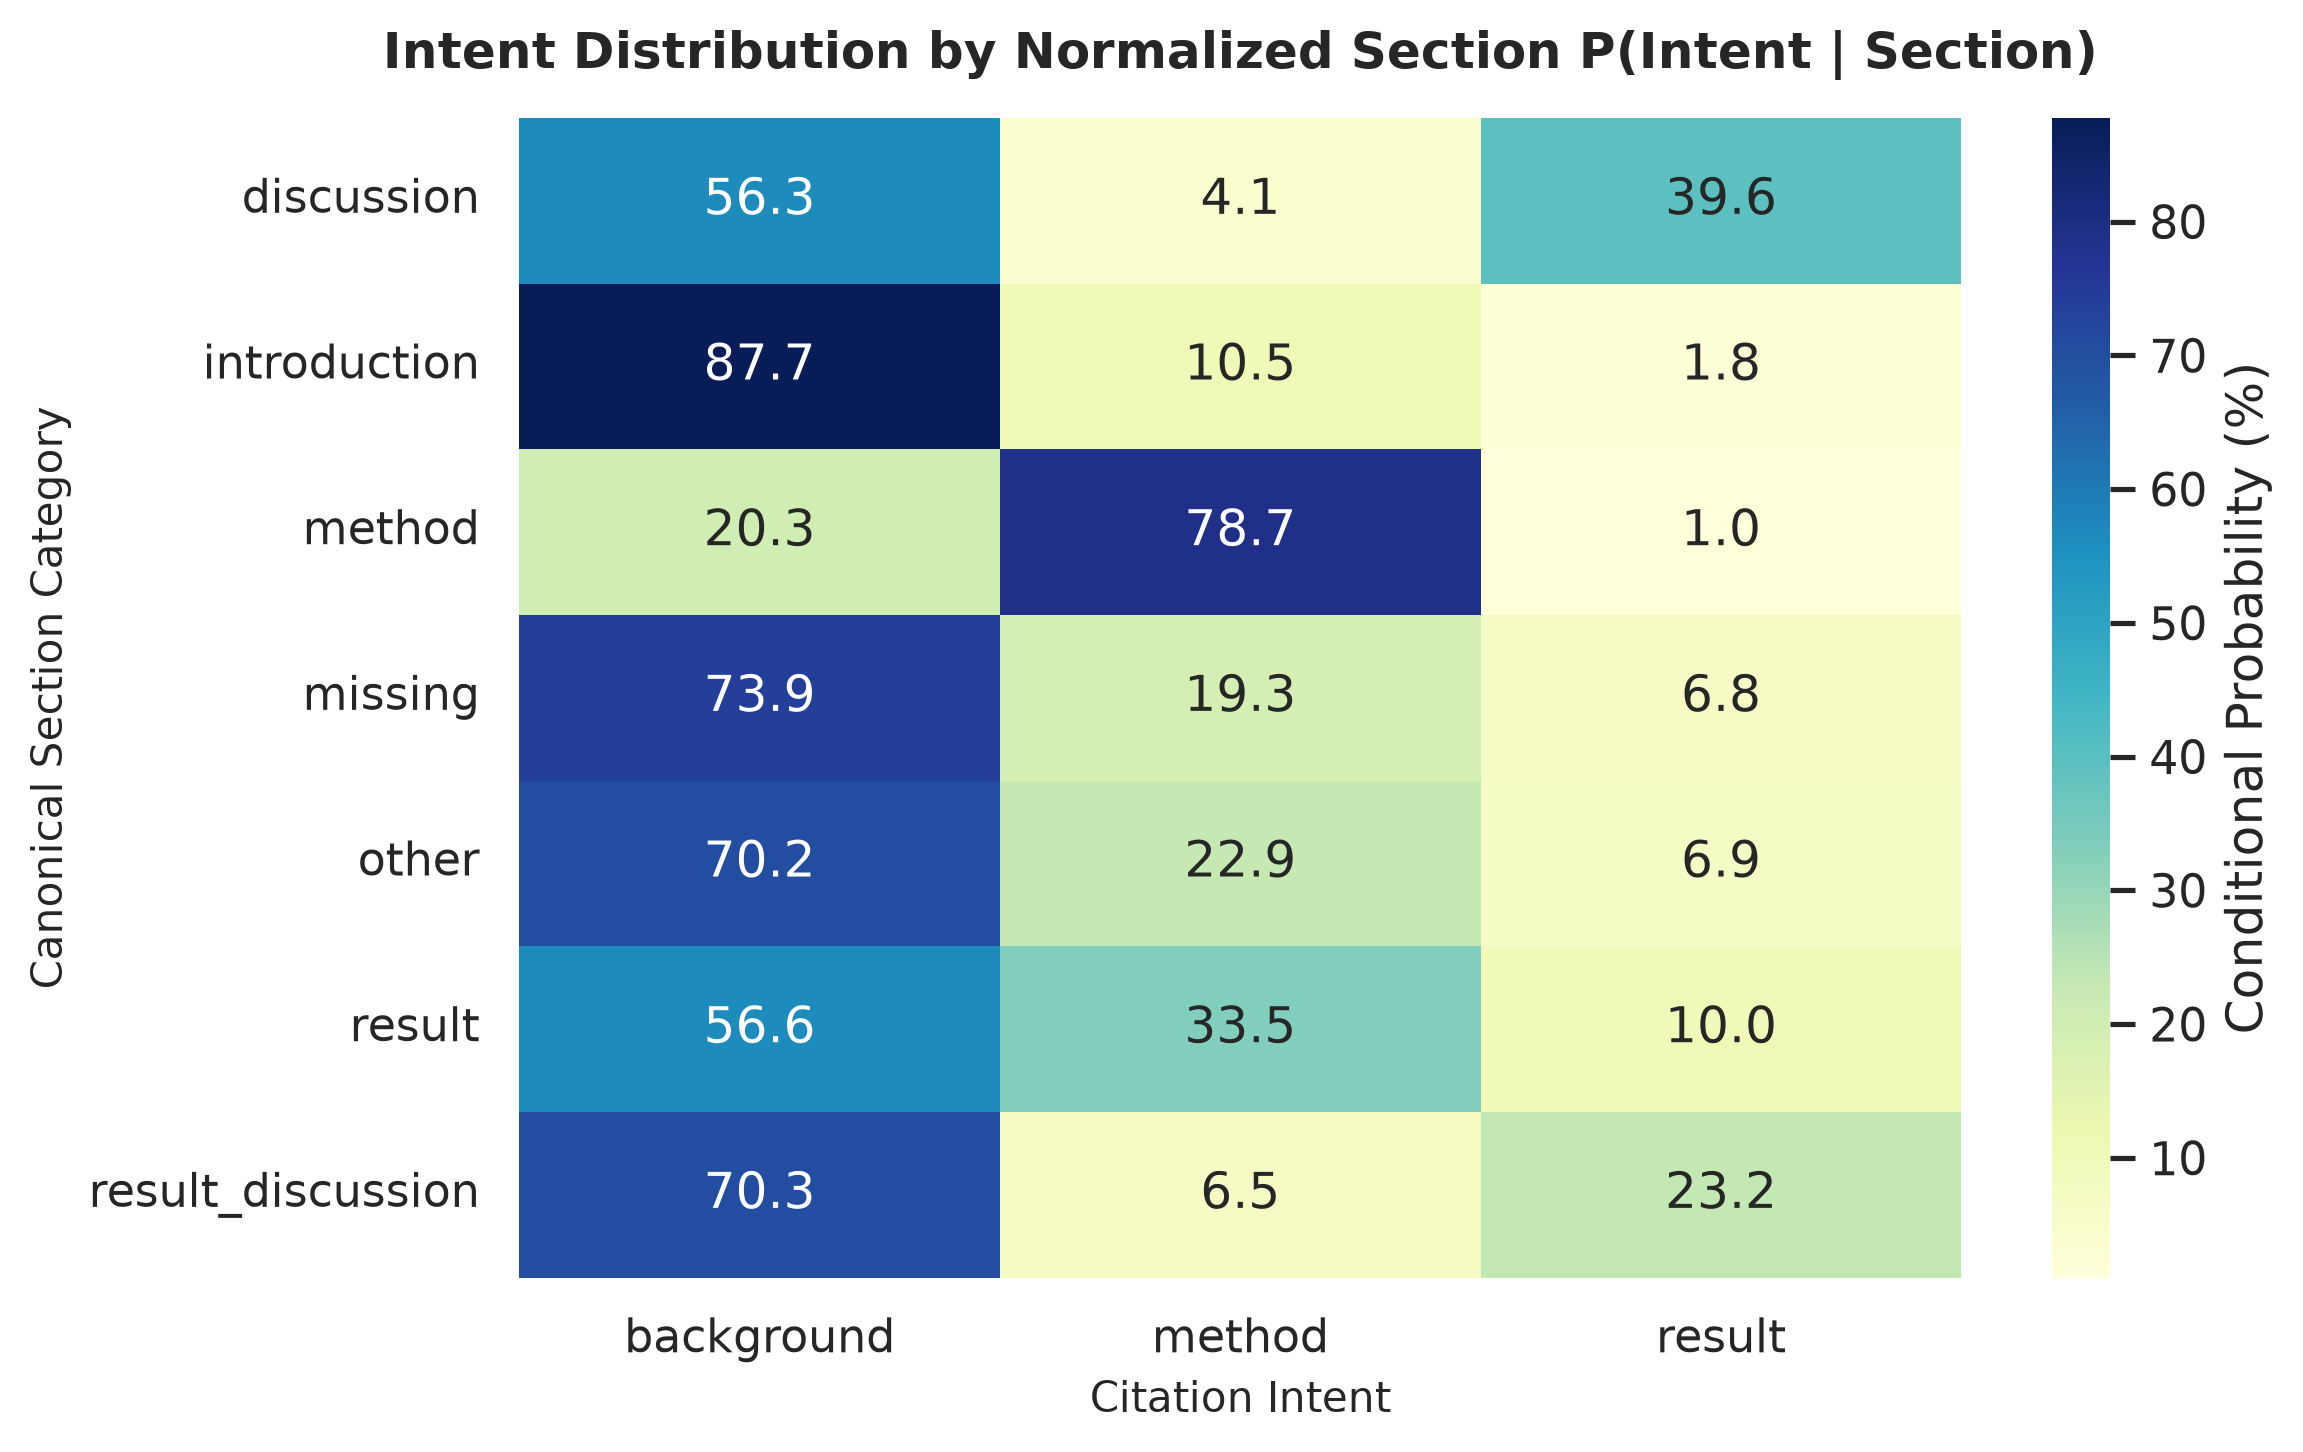

Conditional Probability P(Intent | Normalized Section) [%]:


label_name,background,method,result
section_clean,,,
discussion,56.27,4.12,39.61
introduction,87.75,10.45,1.80
method,20.26,78.71,1.03
missing,73.93,19.31,6.77
other,70.22,22.90,6.88
result,56.55,33.46,9.99
result_discussion,70.27,6.49,23.24


In [6]:
# Process all splits
processed_dfs = {split: build_input_representations(df) for split, df in dfs.items()}

# Display distribution of canonical sections
fig = plot_canonical_section_distribution(processed_dfs)
plt.show()

# Display conditional probability P(Intent | Normalized Section)
fig = plot_canonical_section_contingency(processed_dfs["train"])
plt.show()

# Contingency table numbers
contingency = pd.crosstab(
    processed_dfs["train"]["section_clean"],
    processed_dfs["train"]["label_name"],
    normalize="index"
) * 100
print("Conditional Probability P(Intent | Normalized Section) [%]:")
display(contingency.round(2))

### 7. Concrete Examples of Generated Representations
Inspecting how the exact same citation text appears across the two comparative input formats:

In [7]:
sample_preview = processed_dfs["train"][["sectionName", "section_clean", "label_name", "text_only", "text_section_aware"]].head(3)
for idx, row in sample_preview.iterrows():
    print(f"\n=== Instance #{idx + 1} (Ground Truth: {row['label_name']}) ===")
    print(f"Raw Section:    '{row['sectionName']}' -> Normalized: '{row['section_clean']}'")
    print(f"[Text-only]:     {row['text_only']}")
    print(f"[Section-aware]: {row['text_section_aware']}")


=== Instance #1 (Ground Truth: background) ===
Raw Section:    'Introduction' -> Normalized: 'introduction'
[Text-only]:     However, how frataxin interacts with the Fe-S cluster biosynthesis components remains unclear as direct one-to-one interactions with each component were reported (IscS [12,22], IscU/Isu1 [6,11,16] or ISD11/Isd11 [14,15]).
[Section-aware]: Section: introduction. Citation: However, how frataxin interacts with the Fe-S cluster biosynthesis components remains unclear as direct one-to-one interactions with each component were reported (IscS [12,22], IscU/Isu1 [6,11,16] or ISD11/Isd11 [14,15]).

=== Instance #2 (Ground Truth: background) ===
Raw Section:    'Novel Quantitative Trait Loci for Seminal Root Traits in Barley' -> Normalized: 'other'
[Text-only]:     In the study by Hickey et al. (2012), spikes were sampled from the field at the point of physiological
robinson et al.: genomic regions influencing root traits in barley 11 of 13
maturity, dried, grain threshed